Usual package boilerplate

In [1]:
using Pkg
pkg"activate .; instantiate; precompile"
using CSV, Plots, JSON, BenchmarkTools, Parameters, PerlaTonettiWaugh, DataFrames, Suppressor
gr(fmt = :png)

  Updating registry at `~/.julia/registries/General`
  Updating git-repo `https://github.com/JuliaRegistries/General.git`
Precompiling project...
Precompiling Weave


┌ Info: Recompiling stale cache file /home/arnavsood/.julia/compiled/v1.1/Weave/9EzOc.ji for Weave [44d3d7a6-8a23-5bf8-98c5-b353f8df5ec9]
└ @ Base loading.jl:1184


Plots.GRBackend()

We can instantiate our parameters and settings

In [2]:
parameters = parameter_defaults();
settings = settings_defaults(detailed_ts = []);

We can inspect the experiment

In [3]:
@show parameters.d_0, parameters.d_T;

(parameters.d_0, parameters.d_T) = (3.0426, 2.8383400000000005)


And the distribution of `tstops`:

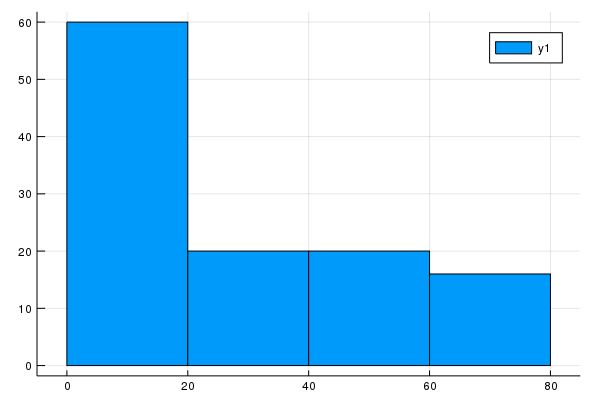

In [4]:
histogram(settings.tstops)

As we can see, the `tstops` are front-loaded. 

And some other relevant settings:

In [5]:
@show settings.fp_iterations;
@show settings.anderson_m; 
@show settings.anderson_beta;

settings.fp_iterations = 500
settings.anderson_m = 5
settings.anderson_beta = 1


Let's run the experiment.

In [6]:
sol = @suppress solve_transition_FP(parameters, settings); # suppresses Sundials output

params_0 = merge(parameters, (d = parameters.d_0,)); 
params_T = merge(parameters, (d = parameters.d_T,));
stationary_0 = stationary_numerical(params_0, settings);
stationary_T = stationary_numerical(params_T, settings);

solved = prepare_results_FP(sol.dynamics_output, stationary_T, stationary_0);
filter!(row -> row.t >= 0, solved); # don't plot pre-shock values

## Welfare

Here's welfare inclusive of the transition path:

In [7]:
lambda_tpath = 100*(consumption_equivalent(solved.U[1], stationary_0.U_bar, parameter_defaults())-1);
@show lambda_tpath;

lambda_tpath = 8.013216599758222


## Plots

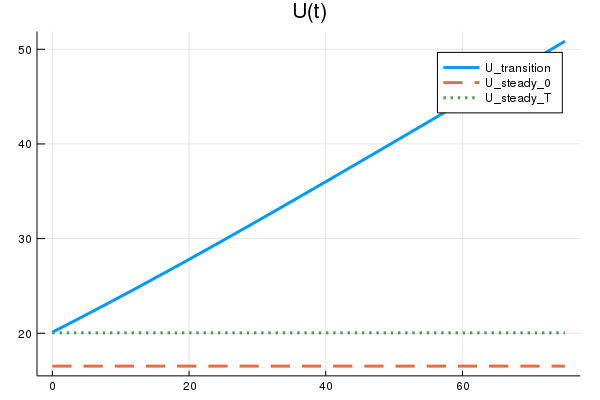

In [8]:
U_steady_0(t) = stationary_0.U_bar
U_steady_T(t) = stationary_T.U_bar

plot(solved.t,
   [solved.U, U_steady_0, U_steady_T],
   label = ["U_transition", "U_steady_0", "U_steady_T"] ,
   title = "U(t)", linestyle = :auto, lw = 3)

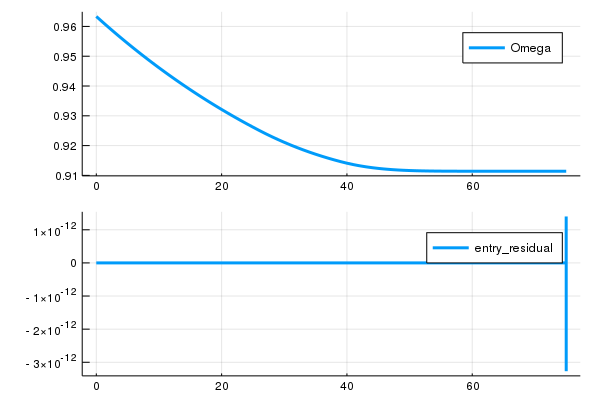

In [9]:
plot_Ω = plot(solved.t, solved.Ω, label = "Omega", lw = 3)
plot_residual = plot(solved.t, solved.entry_residual, label = "entry_residual", lw = 3)
plot(plot_Ω, plot_residual, layout = (2,1))

Here are the static equations

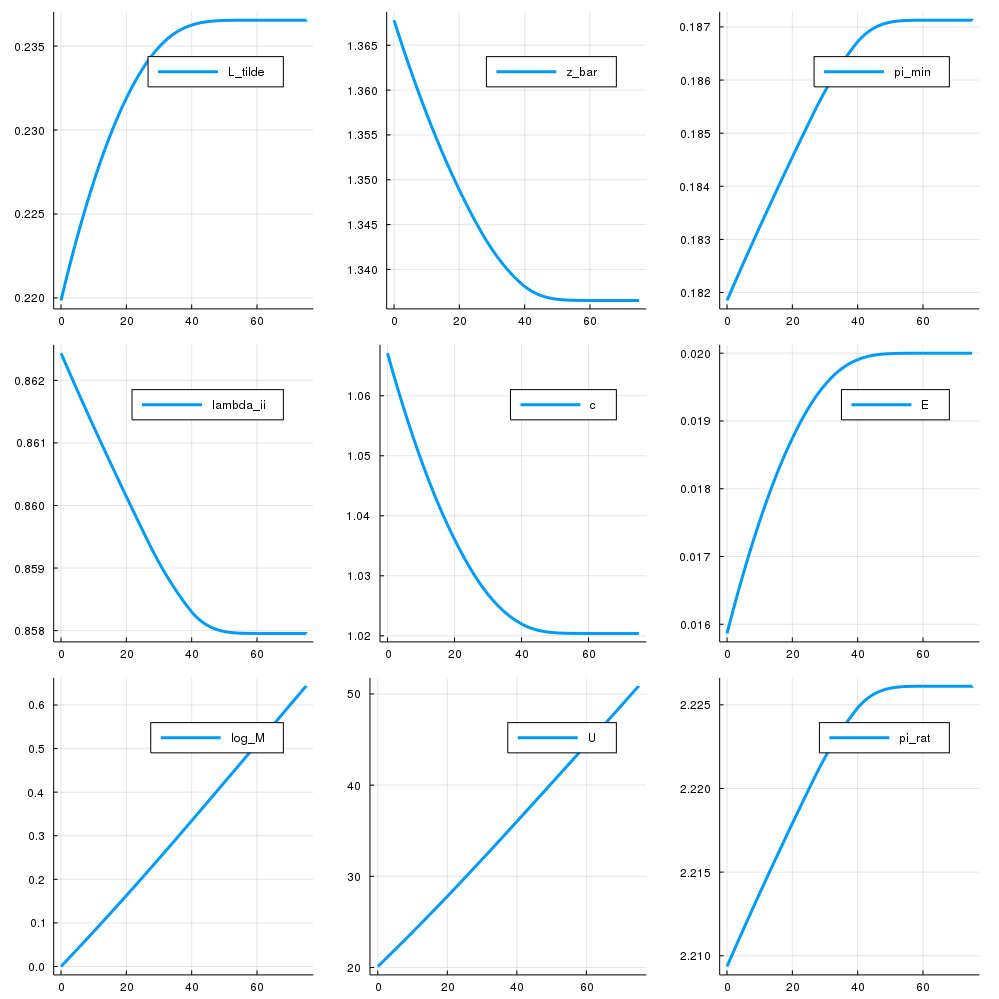

In [10]:
plot1 = plot(solved.t, solved.L_tilde, label = "L_tilde", lw = 3)
plot2 = plot(solved.t, solved.z_bar, label = "z_bar", lw = 3)
plot3 = plot(solved.t, solved.π_min, label = "pi_min", lw = 3)
plot4 = plot(solved.t, solved.λ_ii, label = "lambda_ii", lw = 3)
plot5 = plot(solved.t, solved.c, label = "c", lw = 3)
plot6 = plot(solved.t, solved.E, label = "E", lw = 3)
plot7 = plot(solved.t, solved.log_M, label = "log_M", lw = 3)
plot8 = plot(solved.t, solved.U, label = "U", lw = 3)
plot9 = plot(solved.t, solved.π_rat, label = "pi_rat", lw = 3)
plot(plot1, plot2, plot3, plot4, plot5, plot6, plot7, plot8, plot9, layout=(3,3), size = (1000, 1000))

And a more granular look at welfare

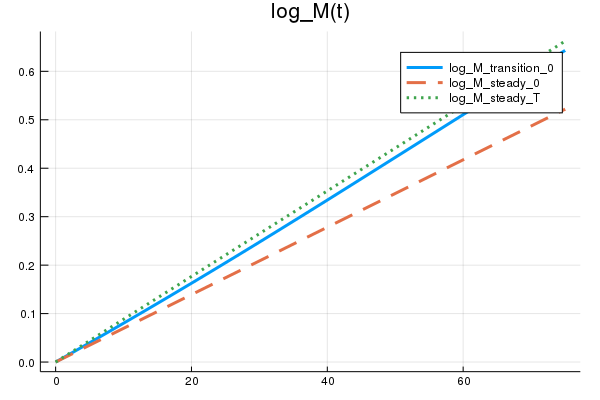

In [11]:
log_M_steady_0(t) = stationary_0.g * t
log_M_steady_T(t) = stationary_T.g * t

plot(solved.t,
    [solved.log_M, log_M_steady_0, log_M_steady_T],
    label = ["log_M_transition_0", "log_M_steady_0", "log_M_steady_T"] ,
    title = "log_M(t)", linestyle = :auto, lw = 3)

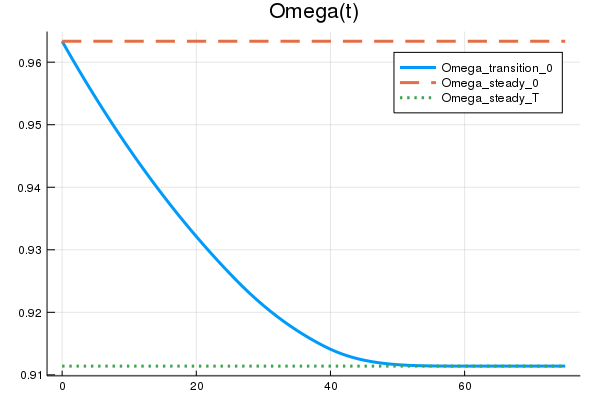

In [12]:
Ω_steady_0(t) = stationary_0.Ω
Ω_steady_T(t) = stationary_T.Ω

plot(solved.t,
    [solved.Ω, Ω_steady_0, Ω_steady_T],
    label = ["Omega_transition_0", "Omega_steady_0", "Omega_steady_T"] ,
    title = "Omega(t)", linestyle = :auto, lw = 3)

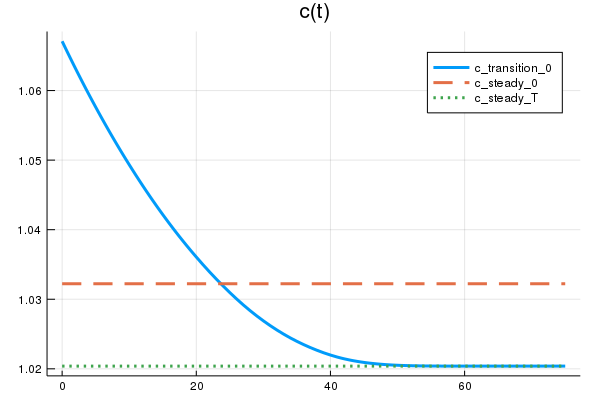

In [13]:
c_steady_0(t) = stationary_0.c
c_steady_T(t) = stationary_T.c

plot(solved.t,
    [solved.c, c_steady_0, c_steady_T],
    label = ["c_transition_0", "c_steady_0", "c_steady_T"] ,
    title = "c(t)", linestyle = :auto, lw = 3)

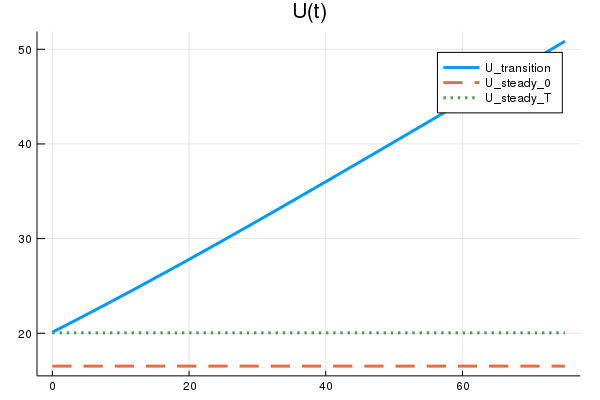

In [14]:
U_steady_0(t) = stationary_0.U_bar
U_steady_T(t) = stationary_T.U_bar

plot(solved.t,
    [solved.U, U_steady_0, U_steady_T],
    label = ["U_transition", "U_steady_0", "U_steady_T"] ,
    title = "U(t)", linestyle = :auto, lw = 3)

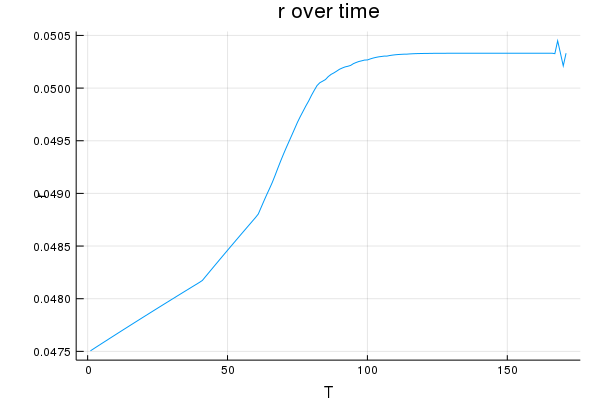

In [15]:
plot(solved.r, legend = false, title = "r over time", xlabel = "T", ylabel = "r")

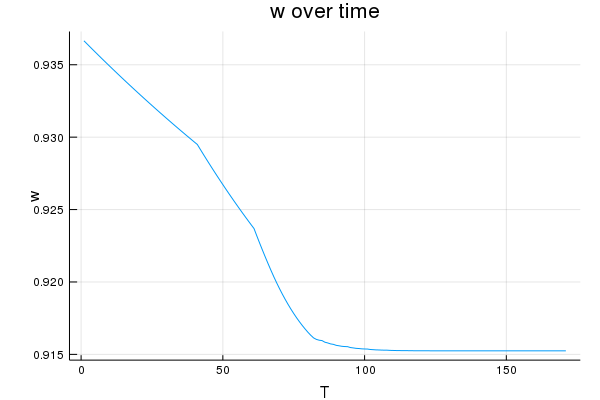

In [16]:
plot(solved.w, legend = false, title = "w over time", xlabel = "T", ylabel = "w")

Here's the labor share breakdown

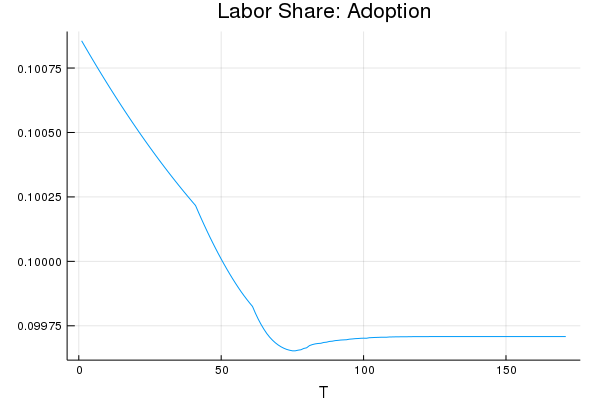

In [17]:
plot(solved.L_tilde_a, legend = false, xlabel = "T", title = "Labor Share: Adoption")

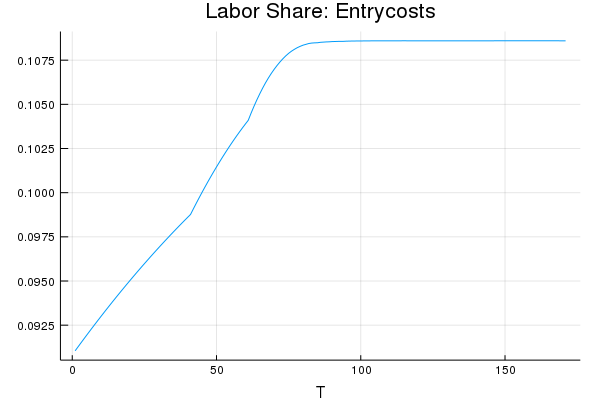

In [18]:
plot(solved.L_tilde_E, legend = false, xlabel = "T", title = "Labor Share: Entrycosts")

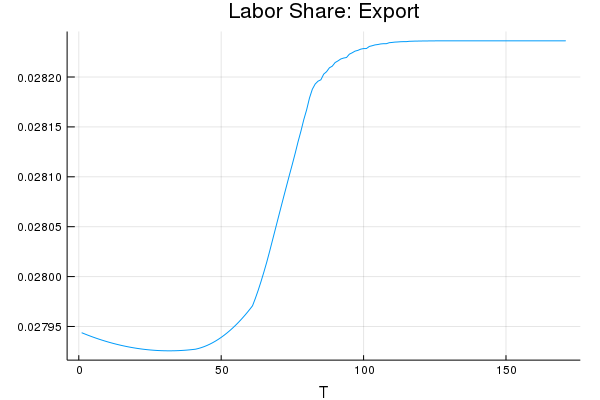

In [19]:
plot(solved.L_tilde_x, legend = false, xlabel = "T", title = "Labor Share: Export")

And the consumption equivalent

In [20]:
T = solved.t[end]
consumption_equivalent(solved.U[1], stationary_0.U_bar, parameter_defaults())

1.0801321659975822